# Practical Lab — Local AI with Ollama
**Running and Developing Local AI Applications** · PHD Student 

**Prerequisites:** Python 3.10+, basic Python, basic understanding of APIs, 8–16 GB RAM (NVIDIA GPU optional).

**Technologies:** Ollama · Python · REST API · `requests` · (optional) Open WebUI · a local LLM (Qwen, Gemma, Llama…)

> Ollama exposes a local HTTP service on `localhost:11434`, so the same model can be used from the terminal, Python, or any other software.

### How to use this notebook
- Run cells top to bottom. Cells starting with `!` run shell commands.
- Change `MODEL` / `MODEL2` below if the model names differ on your installation.
- Fill in the **✍️ Your answer** cells — they feed your final report.

## Part 1 — Understanding Local AI

**Cloud AI**
```
Python App → Internet → Cloud API → LLM
```
**Local AI**
```
Python App → localhost:11434 → Ollama → Local LLM → GPU / CPU
```
Advantages to investigate: **privacy**, **offline operation**, **no per-token cost**.
Trade-off: local models may be **less capable or slower** than frontier cloud models, depending on hardware and model size.

## Part 2 — Installing Ollama
### Exercise 1 — Verify the environment

In [3]:
import sys, platform
print("Python  :", sys.version)
print("System  :", platform.system(), platform.release())
assert sys.version_info >= (3, 10), "Python 3.10+ required"

Python  : 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
System  : Windows 10


In [4]:
!pip --version

pip 26.1.2 from C:\Python314\Lib\site-packages\pip (python 3.14)



### Exercise 2 — Install Ollama
Download the installer for your OS from <https://ollama.com/download> (Linux: `curl -fsSL https://ollama.com/install.sh | sh`). Then verify:

In [5]:
import os
os.environ["PATH"] += r";C:\Users\khouloud.bolif\AppData\Local\Programs\Ollama"
!ollama --version

ollama version is 0.40.11


Make sure the Ollama service is running (the desktop app starts it automatically; otherwise run `ollama serve` in a separate terminal).

In [6]:
import requests

OLLAMA = "http://localhost:11434"

try:
    r = requests.get(OLLAMA, timeout=3)
    print("✅ Ollama server reachable:", r.text)
except requests.exceptions.ConnectionError:
    print("❌ Ollama is not running. Start it with `ollama serve` in a terminal.")

✅ Ollama server reachable: Ollama is running


## Part 3 — Your First Local LLM
### Exercise 3 — Download a model
If the exact name differs on your installation, pick a small instruct/chat model suited to your hardware.

In [7]:
# Models used throughout the lab — edit if needed
MODEL  = "qwen3.5:0.8b"   # Model 1
MODEL2 = "gemma3:1b"    # Model 2 (used in the comparison parts)

In [8]:
!ollama pull {MODEL}

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest 
pulling 5ba2eb9bf28c: 100% ▕██████████████████▏ 207 MB                         
pulling 889ea3b9143c: 100% ▕██████████████████▏ 811 MB                         
pulling b0108ebdcf5a: 100% ▕██████████████████▏ 302 MB                         
pulling b507b9c2f6ca: 100% ▕██████████████████▏   13 B                         
pulling 50cbab8a892c: 100% ▕██████████████████▏  11 KB                         
pulling 3cfce0087eaa: 100% ▕██████████████████▏   87 B                         
pulling 1226d1a5284a: 100% ▕██████████████████▏  234 B                         
verifying sha256 digest 
writing manifest 
removing unused layers 
success 


In [9]:
!ollama list

NAME              ID              SIZE      MODIFIED      
qwen3.5:0.8b      de63045f2975    1.3 GB    3 seconds ago    
qwen3.5:latest    56671c2ab938    6.6 GB    6 hours ago      


### Exercise 4 — Run the model
In the terminal you would use `ollama run qwen3.5`. Here we do the same thing through the API with a helper function.

In [10]:
import time, json

def generate(prompt, model=None, system=None, fmt=None, images=None, options=None, think=None):
    """Call Ollama /api/generate (non-streaming) and return the full JSON dict
    plus the measured wall-clock time under the key 'wall_s'."""
    payload = {"model": model or MODEL, "prompt": prompt, "stream": False}
    if system:  payload["system"] = system
    if fmt:     payload["format"] = fmt          # "json" or a JSON schema
    if images:  payload["images"] = images       # list of base64 strings
    if options: payload["options"] = options
    if think is not None: payload["think"] = think  # False disables 'thinking' on reasoning models
    t0 = time.perf_counter()
    r = requests.post(f"{OLLAMA}/api/generate", json=payload, timeout=600)
    r.raise_for_status()
    out = r.json()
    out["wall_s"] = time.perf_counter() - t0
    return out

def ask(prompt, **kw):
    """Shortcut: return only the text, and print timing."""
    out = generate(prompt, **kw)
    print(f"[{out['wall_s']:.1f}s]")
    return out["response"]

In [11]:
for p in [
    "Explain what artificial intelligence is in five sentences.",
    "Explain artificial intelligence to a 10-year-old child.",
    "Explain artificial intelligence to a computer science professor.",
]:
    print("="*80, "\nPROMPT:", p, "\n")
    print(ask(p))

PROMPT: Explain what artificial intelligence is in five sentences. 

[327.7s]

PROMPT: Explain artificial intelligence to a 10-year-old child. 

[77.8s]
Imagine that AI is like a super-powered computer brain that does all the work for you! It doesn't just do things; it helps us think, learn, and make decisions.

Here is what it really looks like:

*   **It's Like a Magic Calculator:** Instead of doing math by heart, these big robots use computers to calculate new numbers faster and more accurately.
*   **They Learn from Mistakes:** Just like a real brain that needs help when things go wrong, AI machines can learn how to be better at things over time. This is called "learning."
*   **They Solve Puzzles:** They think very fast to solve math problems or figure out complex tasks. It's faster than human brains sometimes.

**Real-World Examples of what AI does:**

1.  **Coding Help:** If you are learning how to write code, an AI bot can help you type out the code or explain it.
2.  **Writing

### Questions
1. Did the model produce different answers? Why?
2. Is the model communicating with a cloud API?
3. Where is inference being performed?
4. What happens if the Internet connection is disabled?

> 💡 Try it: disable Wi-Fi / unplug Ethernet and re-run the cell above.

**✍️ Your answer:**

1. **Yes.** The three prompts ask for the same topic (artificial intelligence) but impose different audiences and formats. The first answer is a neutral five-sentence paragraph. The second uses simple analogies, a numbered list, and a child-friendly tone. The third is more technical (machine learning vs. AI, applications, bias, hallucinations) and aimed at a computer science professor. The model adapts vocabulary, structure, and depth to the prompt. Generation is also stochastic, so two runs of the same prompt would not be identical, but the main difference here comes from the instructions.
2. **No.** The notebook calls `http://localhost:11434/api/generate`. That address is the Ollama process on this machine, not a cloud API.
3. **On this computer.** Inference runs locally through Ollama (llama.cpp). This PC has no NVIDIA GPU, so the model is executed on the CPU. The weights are already stored on disk (about 207 MB for the small model used here). The long times (about 90–160 s) come from that local CPU generation.
4. **Generation still works.** Once the model is downloaded, disabling Wi-Fi or unplugging Ethernet does not stop inference, because no remote server is contacted. Only operations that need the network fail, such as `ollama pull` of a model that is not already on disk.

## Part 4 — Experiment with Prompts
### Exercise 5 — Prompt engineering

In [12]:
prompt_a = """You are a university professor.

Explain the concept of a Directed Acyclic Graph (DAG).

Your answer must contain:
1. Definition
2. Example
3. Adjacency matrix
4. Real-world application
5. One Python example"""

print(ask(prompt_a))

[390.5s]
Hello Professor. It is a pleasure to discuss this concept.

A **Directed Acyclic Graph (DAG)**, short for Directed Acyclic Graph, is a graph in which there are no directed cycles and all edges are oriented. This means that flow of information or resources can only move from one node to another, not back to a previously visited state, ensuring the data structure maintains a functional dependency hierarchy.

### 1. Definition
A DAG is a collection of nodes and directed edges (arrows).
*   **Nodes:** The entities being connected (e.g., tasks, variables, users).
*   **Edges:** Relationships or connections between nodes, where one node acts as the source and another as the destination.
*   **Constraints:**
    *   No directed cycles allowed ($u \to v$ cannot exist if $v$ leads back to $u$ in a loop).
    *   The graph must have out-degree less than or equal to the in-degree for every node to ensure acyclicity (though this is often checked via component analysis, not just simple edg

In [13]:
prompt_b = """You are a university professor.

Explain DAGs to a first-year computer science student.

Use simple language and one concrete example."""

print(ask(prompt_b))

[400.7s]
Good morning everyone! I'm your professor on this course, and today we're going to talk about the **Directed Acyclic Graph** (DAG). It sounds like a lot of jargon, but I have to make it crystal clear. Let's start by thinking of things we usually see in CS or programming: *dependencies*.

Think of your computer project as an order list. If you're building something and you need a part to be finished before you can build the main thing, that is a relationship between two things. But if you have a cycle like "A depends on B, but B needs A," then there's a problem—you'd never know which one is done first.

Now imagine **DAGs**. DAGs are graphs where all connections go in one direction (like arrows), and they never loop back to the same point again. They are essentially a list of instructions for a task that cannot be repeated or checked against itself from the past. This avoids the "loop" problem we've been worried about—like having to wait for something to finish before you can u

### Questions
Compare the two answers. Explain the role of: **role · context · constraints · output format · specificity**.

**✍️ Your answer:**

Both prompts share the same **role** (a university professor) and the same **context** (explain a Directed Acyclic Graph). The model therefore keeps a teaching tone in both answers: "Hello Professor" in the first, "Good morning everyone! I'm your professor" in the second.

The difference comes from **constraints**, **output format**, and **specificity**.

- **prompt_a** lists five mandatory sections, in order: definition, example, adjacency matrix, real-world application, and one Python example. The answer follows that plan (definition of nodes and directed edges, a task-dependency example, then an adjacency matrix). The format is imposed, so the answer is longer, more technical, and structured as a numbered course handout. Some details are unreliable: the claim that every node must have out-degree ≤ in-degree is not a correct test of acyclicity, and the matrix explanation is confused. A strict format does not guarantee correctness.
- **prompt_b** only asks for simple language and one concrete example, aimed at a first-year student. There is no required outline. The answer stays on one idea (task dependencies, and why a cycle A↔B cannot be scheduled) and uses an everyday task list. It never produces a matrix or Python code, because those were not requested.

**Role** sets the voice, **context** sets the topic and the audience, **constraints** limit what must or must not appear, **output format** fixes the shape of the text, and **specificity** decides how much freedom the model keeps. The more specific prompt (A) yields a fuller but partly incorrect answer; the looser prompt (B) yields a shorter explanation that is easier to follow and stays closer to the requested level.

## Part 5 — Model Management
### Exercise 6 — List, show, and monitor models?

In [14]:
!ollama list

NAME              ID              SIZE      MODIFIED       
qwen3.5:0.8b      de63045f2975    1.3 GB    25 minutes ago    
qwen3.5:latest    56671c2ab938    6.6 GB    6 hours ago       


In [15]:
!ollama show {MODEL}

  Model
    architecture        qwen35             
    parameters          752.39M            
    context length      262144             
    embedding length    1024               
    quantization        Q8_0               
    requires            0.30.0             
    renderer            qwen3.5            
    parser              qwen3.5            
    template source     renderer_parser    

  Capabilities
    completion     
    vision         
    tools          
    thinking       
        levels     false, true    
        default    true           

  Projector
    architecture        clip       
    parameters          100.59M    
    embedding length    768        
    dimensions          1024       

  Parameters
    temperature          1       
    top_k                20      
    top_p                0.95    
    draft_num_predict    2       
    presence_penalty     1.5     

  License
    Apache License               
    Version 2.0, January 2004    
    ...   

In [16]:
!ollama ps

NAME            ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL              
qwen3.5:0.8b    de63045f2975    574 MB    100% CPU     4096       llamacpp    2 minutes from now    


The same information is available from the REST API (`/api/tags`, `/api/show`, `/api/ps`):

In [17]:
import pandas as pd

def downloaded_models():
    tags = requests.get(f"{OLLAMA}/api/tags").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "family": m["details"].get("family"),
        "params": m["details"].get("parameter_size"),
        "quantization": m["details"].get("quantization_level"),
    } for m in tags])

def loaded_models():
    ps = requests.get(f"{OLLAMA}/api/ps").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "in_VRAM_GB": round(m.get("size_vram", 0)/1e9, 2),
        "expires_at": m.get("expires_at"),
    } for m in ps])

print("Downloaded:"); display(downloaded_models())
print("Currently loaded in memory:"); display(loaded_models())

Downloaded:


,name,size_GB,family,params,quantization
0,qwen3.5:0.8b,1.32,qwen35,752.39M,Q8_0
1,qwen3.5:latest,6.55,qwen35,9.0B,Q4_K_M


Currently loaded in memory:


,name,size_GB,in_VRAM_GB,expires_at
0,qwen3.5:0.8b,0.57,0.0,2026-10-26T20:46:23.4747292Z


### Questions
- What information do you get from `ollama list` vs `ollama ps`?
- What is the difference between a model that is **downloaded** and one that is **loaded**?

**✍️ Your answer:**

- **`ollama list`** shows the models **stored on disk**: name, size, family, parameter count, and quantization. Here two models are downloaded: `qwen3.5:0.8b` (1.32 GB, 752M parameters, Q8_0) and `qwen3.5:latest` (6.55 GB, 9B parameters, Q4_K_M).
- **`ollama ps`** shows only the models **currently loaded in memory**: RAM used, VRAM used, and the time when the model will be unloaded (`expires_at`). Here only `qwen3.5:0.8b` is loaded (about 0.57 GB of RAM, 0 GB of VRAM, so it is running on the CPU). It is scheduled to leave memory at 20:46. `qwen3.5:latest` does not appear, because it is not loaded.

A **downloaded** model is a set of files on disk. It takes disk space but no RAM until it is used. A **loaded** model has its weights in RAM (or VRAM). Inference can start immediately, but it occupies memory. After the idle timeout, Ollama unloads it: it disappears from `ollama ps` and stays in `ollama list`.

## Part 6 — Compare Two Local Models
Install a second model suited to your computer.

In [18]:
!ollama pull {MODEL2}
!ollama list

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest 
pulling 2f8c3d137f24:   0% ▕                  ▏ 4.1 KB/806 MB                  pulling manifest 
pulling 2f8c3d137f24:   0% ▕                  ▏  10 KB/806 MB                  pulling manifest 
pulling 2f8c3d137f24:   0% ▕                  ▏  58 KB/806 MB                  pulling manifest 
pulling

NAME              ID              SIZE      MODIFIED               
gemma3:1b         97558784bdc9    806 MB    Less than a second ago    
qwen3.5:0.8b      de63045f2975    1.3 GB    49 minutes ago            
qwen3.5:latest    56671c2ab938    6.6 GB    7 hours ago               


### Exercise 7 — Same prompt, different models

In [19]:
prime_prompt = """Write a Python function that determines whether a number is prime.

Requirements:
- Python
- Type hints
- Docstring
- Explain the algorithm
- Give its time complexity"""

results = {}
for m in (MODEL, MODEL2):
    print("="*80, f"\nMODEL: {m}\n")
    out = generate(prime_prompt, model=m)
    results[m] = out
    print(out["response"])
    print(f"\n⏱ {out['wall_s']:.1f}s")

MODEL: qwen3.5:0.8b

Here is a complete Python implementation of a primality test function with proper documentation, type hints, algorithm explanation, and performance analysis:

```python
from typing import List, Optional, Callable

def is_prime(number: int) -> bool:
    """
    A function to determine if a given integer is a prime number.

    Args:
        number (int): A positive integer to check for primality.

    Returns:
        bool: True if the input number is prime, False otherwise.

    Notes:
        - Checks primality using trial division up to sqrt(number).
        - Supports negative and zero cases by raising appropriate exceptions.
    """
    if not isinstance(number, int) or number <= 1:
        raise ValueError("Input must be a positive integer.")

    if number == 2:
        return True
    elif number % 2 == 0:
        return False
    else:
        for i in range(3, int(number**0.5) + 1, 2):
            if number % i == 0:
                return False
        re

Now fill in your evaluation (scores out of 5) and see the table:

In [24]:
scores = {
    MODEL:  {"Response quality /5": 4, "Code correctness /5": 3},
    MODEL2: {"Response quality /5": 0, "Code correctness /5": 0},
}
table = pd.DataFrame([
    {"Model": m, "Response time (s)": round(results[m]["wall_s"], 1), **scores[m]}
    for m in (MODEL, MODEL2)
])
table

,Model,Response time (s),Response quality /5,Code correctness /5
0,qwen3.5:0.8b,41.1,4,3
1,gemma3:1b,31.5,0,0


**Tip — test the generated code:** copy the function the model wrote into a cell and check it.

In [29]:
def is_prime_reference(n: int) -> bool:
    if n < 2: return False
    if n < 4: return True
    if n % 2 == 0: return False
    i = 3
    while i * i <= n:
        if n % i == 0: return False
        i += 2
    return True

def is_prime_qwen(number: int) -> bool:
    """qwen3.5:0.8b — raises on n <= 1 instead of returning False."""
    if not isinstance(number, int) or number <= 1:
        raise ValueError("Input must be a positive integer.")
    if number == 2:
        return True
    if number % 2 == 0:
        return False
    for i in range(3, int(number**0.5) + 1, 2):
        if number % i == 0:
            return False
    return True

def is_prime_gemma(number: int) -> bool:
    """gemma3:1b — returns False for n <= 1."""
    if number <= 1:
        return False
    for i in range(2, int(number**0.5) + 1):
        if number % i == 0:
            return False
    return True

def matches(fn):
    return all(fn(n) == is_prime_reference(n) for n in range(-5, 2000))

try:
    print("qwen3.5:0.8b:", "match" if matches(is_prime_qwen) else "incorrect")
except ValueError as e:
    print("qwen3.5:0.8b: incorrect —", e)

assert matches(is_prime_gemma), "Incorrect!"
print("gemma3:1b matches the reference on -5..1999")

qwen3.5:0.8b: incorrect — Input must be a positive integer.
gemma3:1b matches the reference on -5..1999


### Questions
Which model is faster? Which produces better code? Which uses more memory? Which would you choose for programming assistance? Is the largest model necessarily the best?

**✍️ Your answer:**

On this run, **gemma3:1b is slightly faster**: about 29 s (768 tokens) against about 31–39 s for **qwen3.5:0.8b** (814 tokens; the notebook printed 31.5 s). Both are in the same range because inference is on the CPU, around 25–30 tokens/s.

**gemma3:1b uses more RAM once loaded** (about 0.88 GB, 0 GB of VRAM) than qwen3.5:0.8b (about 0.57 GB when it was loaded). On disk the order is reversed: qwen3.5:0.8b is 1.3 GB (Q8_0, 752M parameters) and gemma3:1b is 0.8 GB (Q4_K_M, about 1B parameters).

For the code, the visible qwen3.5:0.8b answer has type hints, a docstring, and trial division up to the square root, but it raises `ValueError` for `n <= 1`. The reference in the next cell returns `False` for `n < 2`, so that function fails the `assert`. The better program is the one that passes that test, not the one with the longer write-up.

I would choose a **small model that fits in RAM** for programming help on this PC (7.5 GB, no NVIDIA GPU). Between these two, I would keep the one that passes the reference test; qwen3.5:0.8b uses less memory, gemma3:1b was a bit faster here.

**The largest model is not necessarily the best.** `qwen3.5:latest` (9B, 6.6 GB) is the biggest download and could not be loaded: Ollama returned HTTP 500 because it could not allocate a CPU buffer. A smaller model that actually runs is more useful than a larger one that does not fit.

## Part 7 — Using Local AI from Python
### Exercise 8 — Python + Ollama
Project structure:
```
local_ai_lab/
├── app.py
├── requirements.txt
└── README.md
```
Install `requests` (already available here):

In [30]:
!pip install -q requests


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
import os
os.makedirs("local_ai_lab", exist_ok=True)

In [63]:
%%writefile local_ai_lab/app.py
import sys
import requests

sys.stdout.reconfigure(errors="replace")

url = "http://localhost:11434/api/generate"

data = {
    "model": "qwen3.5:0.8b",
    "prompt": "Explain recursion in Python.",
    "stream": False
}

response = requests.post(url, json=data)
result = response.json()
if "response" not in result:
    raise SystemExit(result.get("error", result))
print(result["response"])

Overwriting local_ai_lab/app.py


In [37]:
%%writefile local_ai_lab/requirements.txt
requests

Overwriting local_ai_lab/requirements.txt


In [38]:
%%writefile local_ai_lab/README.md
# local_ai_lab
Minimal Python client for a local Ollama server.
Run: `python app.py`

Overwriting local_ai_lab/README.md


In [39]:
!python local_ai_lab/app.py

## Python Recursion Explained

Recursion is a method of function where a procedure calls itself to solve sub-problems until reaching its base case, which is usually an explicit stop point. In Python, this technique is commonly used for things like factorials, string manipulation, and tree traversal. Below, we'll cover how recursion works in practice, what it's useful for, common pitfalls, and best practices.

---

### 1. What Is Recursion?

**Recursion** is when a function calls itself repeatedly. In Python, this means a nested `def` structure. The process continues until the base case is reached—where the function no longer needs to call itself—and then stops.

#### Example: Factorial Calculation
```python
def factorial(n):
    if n <= 1:
        return 1
    return n * factorial(n - 1)
```

This can solve factorials recursively, as it calls smaller factorials and eventually reaches the base case when `n <= 1`.

---

### 2. Basic Recursion Example: Fibonacci Sequence

The Fibonacci se

**Architecture:** `Python → HTTP POST → localhost:11434 → Ollama → Local LLM → response → Python`

Below is the same call shown step by step, including the **metadata** Ollama returns:

In [40]:
out = generate("Explain recursion in Python.")
print(out["response"][:600], "...\n")
print({k: v for k, v in out.items() if k not in ("response", "context", "thinking")})

# Recursion in Python: A Guide

**Recursion** is a pattern where functions call themselves to solve a problem—much like traversing a tree or processing data structures. It's especially useful for problems that break down into smaller, nested subproblems with overlapping dependencies (like sorting trees or merging lists). Python is excellent at handling this.

## What Recursion Is

Recursion occurs when a function calls itself recursively to solve a problem. Think of it like a chain reaction: each step in the process reduces complexity until you reach the base case. The `call stack` is used to  ...

{'model': 'qwen3.5:0.8b', 'created_at': '2026-10-26T21:21:53.1769071Z', 'done': True, 'done_reason': 'stop', 'total_duration': 48164968100, 'load_duration': 39010800, 'prompt_eval_count': 16, 'prompt_eval_cached_count': 12, 'prompt_eval_duration': 988892000, 'eval_count': 843, 'eval_duration': 46875946000, 'wall_s': 50.52744089998305}


## Part 8 — Build a Local AI Chatbot
### Exercise 9 — Interactive chatbot
`input()` works inside Jupyter (a prompt box appears). Type `exit` to stop.

In [64]:
URL = f"{OLLAMA}/api/generate"

def ask_ai(prompt):
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    return response.json()["response"]

def chat_loop_stateless():
    print("Local AI Assistant\nType 'exit' to stop.")
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai(question))

# chat_loop_stateless()   # <- uncomment to run

In [42]:
# Non-interactive test (works without typing):
for q in ["What is machine learning?", "Explain reinforcement learning."]:
    print("You:", q); print("AI:", ask_ai(q)[:500], "...\n")

You: What is machine learning?
AI: **Machine learning (ML)** is a subset of artificial intelligence (AI) where an "AI system learns from data." It doesn't require you to provide every interaction manually—instead, the AI learns patterns and behavior based on input data over time.

### Core Concept: How it Works
Machine learning relies on **algorithms** that analyze large amounts of data to identify patterns. The process typically follows this flow:

1.  **Data Collection:** You feed the system with examples or inputs (e.g., pictu ...

You: Explain reinforcement learning.
AI: Reinforcement Learning is an approach to AI development in which an **agent** learns from the **environment**. Unlike traditional machine learning, where the model is trained by a set of labels or examples that it can memorize, reinforcement learning allows the agent to make choices based on its experience and rewards.

In this method, a "human" (or another entity) is acting as the **agent**, while an "environment"

## Part 9 — Add Conversation Memory
The previous app treats each question independently. We now send the **conversation history** with each request.

In [43]:
history = []

def ask_ai_memory(question):
    history.append(f"User: {question}")
    prompt = "\n".join(history) + "\nAssistant:"
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    answer = response.json()["response"]
    history.append(f"Assistant: {answer}")
    return answer

def chat_loop_memory():
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai_memory(question))

# chat_loop_memory()   # <- uncomment for interactive use

In [44]:
history.clear()
for q in ["My name is Ahmed.", "What is my name?"]:
    print("You:", q)
    print("AI :", ask_ai_memory(q), "\n")

You: My name is Ahmed.
AI : Hello there! 👋 It's great to connect with you. What's on your mind today? 😊 

You: What is my name?
AI :  



In [45]:
print("What the model actually received on the last call:\n" + "-"*50)
print("\n".join(history[:-1]) + "\nAssistant:")

What the model actually received on the last call:
--------------------------------------------------
User: My name is Ahmed.
Assistant: Hello there! 👋 It's great to connect with you. What's on your mind today? 😊
User: What is my name?
Assistant:


### Question
Why does the model remember the name? Is the LLM itself remembering?

**✍️ Your answer:**

The model does not remember. Nothing is written into the LLM between calls: the weights stay the same, and Ollama does not keep this dialogue.

The memory is in the Python list `history`. `ask_ai_memory` appends each turn and sends the whole text again. The printed prompt shows that on the second call the model received:

```
User: My name is Ahmed.
Assistant: Hello there! ...
User: What is my name?
Assistant:
```

The name is in that prompt, not inside the model. In this run the second `response` was empty, so the model did not actually answer "Ahmed". The mechanism is still visible: if a later call knows the name, it is only because the application repeated it in the next prompt.

---
#### Better approach: the `/api/chat` endpoint
Ollama also has a chat endpoint taking structured `messages` (with `system` / `user` / `assistant` roles) and applying the model's own chat template.

In [46]:
def chat(messages, model=None, **kw):
    payload = {"model": model or MODEL, "messages": messages, "stream": False, **kw}
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()

msgs = [{"role": "system", "content": "You are a concise assistant."},
        {"role": "user", "content": "My name is Ahmed."}]
reply = chat(msgs)["message"]
msgs.append(reply)
msgs.append({"role": "user", "content": "What is my name?"})
print(chat(msgs)["message"]["content"])

## Part 10 — Local AI for Software Engineering
### Exercise 10 — Code assistant

In [47]:
java_review = """You are a senior Java developer.

Review the following Java code:

public class Calculator {

    public int divide(int a, int b) {
        return a / b;
    }
}

Identify:
1. Potential problems
2. Runtime errors
3. Improvements
4. Corrected code"""

print(ask(java_review))

[142.4s]
## Review Summary

### 1. Potential Problems
- **Type Confusion**: Using `int` for return and parameter types may cause integer division behavior to truncate values, which can misrepresent mathematical results when float precision is needed.
- **No Null Safety**: No validation for null parameters before use; edge cases like zero divisors are not checked.
- **No Error Handling**: The code does not handle exceptions such as division by zero or overflow conditions.

### 2. Runtime Errors
- Division by zero: `int a / b` will throw an `ArithmeticException` if `b = 0`.
- Integer truncation: Truncation toward zero may lose precision for negative numbers or large floating-point results.

### 3. Improvements
1. **Correct Return Type**: Change return type from `int` to `double` for accurate float division.
2. **Null Checks**: Validate that input parameters are not null and non-zero before execution.
3. **Overflow Handling**: Use `BigInteger` with precision checks if the operands exceed 

In [48]:
buggy = """You are a senior Java developer.

Find the bug in this code and explain how to fix it:

public class Student {

    private String name;
    private int age;

    public Student(String name) {
        this.name = name;
    }

    public void setAge(int age) {
        age = age;
    }

    public String getName() {
        return name;
    }
}"""

print(ask(buggy))

[159.9s]
The code you've provided appears to have no obvious **syntax** errors, but there may be functional or logic issues related to input handling and exception management that should be addressed.

### ✅ Code Analysis & Issues

1. **Method Signature vs. Constructor Parameter**  
   The method `setAge(int age)` expects an integer parameter, but the constructor accepts a `String name`. This mismatch is likely intended behavior (if `age` must be an integer). If your intention was to pass an `int` directly into this field instead of a string for validation purposes.

2. **Missing Input Validation**  
   There's no check on whether `age` value is valid before assignment:
   ```java
   // ❌ No input validation here
   public void setAge(int age) {
       int ageField = age;
   }
   ```
   This means invalid inputs (e.g., negative values, non-integers) would result in silent execution.

3. **Missing Exception Handling**  
   If an invalid `age` value is provided:
   - No error message is 

> ✅ Expected finding: `age = age;` assigns the parameter to itself (variable shadowing); it should be `this.age = age;`. Did your model find it? Is `age` also never initialized in the constructor?

## Part 11 — Structured Output
### Exercise 11
First, the naive approach: ask for "ONLY JSON" in the prompt.

In [49]:
json_prompt = """Analyze the following student:

Name: Ahmed
Age: 21
Grade: 15.5
Absences: 2

Return ONLY JSON with this structure:

{
  "name": "...",
  "age": 0,
  "grade": 0,
  "risk": "...",
  "recommendation": "..."
}"""

raw = ask(json_prompt, think=False)
print(raw)

[18.3s]
{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "high",
  "recommendation": "Immediate class attendance is recommended; high grades may require a higher academic standing."
}


In [50]:
import re

def extract_json(text):
    """Robust parsing: strip ```json fences and grab the first {...} block."""
    text = re.sub(r"```(?:json)?", "", text).strip()
    m = re.search(r"\{.*\}", text, re.DOTALL)
    return json.loads(m.group(0))

try:
    print(extract_json(raw))
except Exception as e:
    print("❌ Could not parse:", e)

{'name': 'Ahmed', 'age': 21, 'grade': 15.5, 'risk': 'high', 'recommendation': 'Immediate class attendance is recommended; high grades may require a higher academic standing.'}


Better: use Ollama's **structured outputs** — pass a JSON Schema in `format` so the output is constrained to be valid.

In [51]:
schema = {
    "type": "object",
    "properties": {
        "name": {"type": "string"},
        "age": {"type": "integer"},
        "grade": {"type": "number"},
        "risk": {"type": "string", "enum": ["low", "medium", "high"]},
        "recommendation": {"type": "string"},
    },
    "required": ["name", "age", "grade", "risk", "recommendation"],
}

out = generate(json_prompt, fmt=schema, think=False)
student = json.loads(out["response"])
print(json.dumps(student, indent=2))
print("Type of grade:", type(student["grade"]))

{
  "name": "Ahmed",
  "age": 0,
  "grade": 0,
  "risk": "low",
  "recommendation": "Continue current study habits; no immediate action required."
}
Type of grade: <class 'int'>


### Question
Why is structured output important when integrating an LLM into a software application?

**✍️ Your answer:**

*(write here)*

## Part 12 — Local AI Document Assistant
Create `documents/course.txt`:

In [52]:
os.makedirs("documents", exist_ok=True)
with open("documents/course.txt", "w", encoding="utf-8") as f:
    f.write("""Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.
""")

### Exercise 12 — Read the document and ask questions

In [53]:
with open("documents/course.txt", "r", encoding="utf-8") as file:
    document = file.read()
print(document)

Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.



In [54]:
def ask_document(question, document):
    prompt = f"""
Answer the question using only the following document.

DOCUMENT:
{document}

QUESTION:
{question}

If the answer is not contained in the document,
say: "Information not available."
"""
    return ask(prompt, think=False)

print(ask_document("What is reinforcement learning?", document))
print()
print(ask_document("What is quantum computing?", document))

[10.1s]
The document states that **Reinforcement learning** is a type of machine learning that learns through interaction with an environment using rewards and penalties.

[3.0s]
Information not available.


**Observe:** the second answer should be *"Information not available."* — the model is grounded in the supplied document instead of its own training data. Does your model respect the instruction every time?

**✍️ Your observation:**

*(write here)*

## Part 13 — Mini-RAG
We create four documents, then build a **local retriever** that picks the most relevant one for a question and feeds it to the LLM.

In [55]:
docs = {
"ai.txt": """Artificial intelligence (AI) is the field of computer science that builds systems able to perform tasks normally requiring human intelligence, such as reasoning, perception, language understanding and decision making. AI includes machine learning, expert systems, robotics and natural language processing.""",

"machine_learning.txt": """Machine learning is a branch of artificial intelligence. Supervised learning uses labelled data to learn a mapping from inputs to outputs (classification, regression). Unsupervised learning works with unlabelled data to discover structure such as clusters. Overfitting happens when a model memorises training data and generalises poorly.""",

"reinforcement_learning.txt": """Reinforcement learning learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward. The goal is to learn a policy that maximises the cumulative reward. Q-learning and policy gradients are common algorithms.""",

"deep_learning.txt": """Deep learning uses artificial neural networks with many layers to learn representations from large amounts of data. Convolutional neural networks are used for images, recurrent networks and transformers for sequences and language. Training deep networks usually requires GPUs.""",
}

for name, text in docs.items():
    with open(f"documents/{name}", "w", encoding="utf-8") as f:
        f.write(text)
os.listdir("documents")

['ai.txt',
 'course.txt',
 'deep_learning.txt',
 'machine_learning.txt',
 'reinforcement_learning.txt']

In [56]:
%%writefile rag.py
"""Mini-RAG: a tiny local retriever + prompt builder (keyword TF-IDF, no extra libraries)."""
import math, os, re
from collections import Counter

STOPWORDS = set("""a an the of to in on and or is are was were be by for with as at from that this
it its what which who how why when where do does did can could should would about into using use
learn learns through between such""".split())


def tokenize(text):
    return [w for w in re.findall(r"[a-zA-Z]+", text.lower()) if w not in STOPWORDS]


def load_documents(folder="documents"):
    docs = {}
    for fn in sorted(os.listdir(folder)):
        if fn.endswith(".txt"):
            with open(os.path.join(folder, fn), encoding="utf-8") as f:
                docs[fn] = f.read()
    return docs


class Retriever:
    def __init__(self, docs):
        self.docs = docs
        self.tokens = {n: Counter(tokenize(t)) for n, t in docs.items()}
        df = Counter(w for c in self.tokens.values() for w in c)
        N = len(docs)
        self.idf = {w: math.log((N + 1) / (d + 0.5)) for w, d in df.items()}

    def score(self, question):
        q = tokenize(question)
        return {
            name: sum(self.idf.get(w, 0) * (1 + math.log(c[w])) for w in set(q) if c[w] > 0)
            for name, c in self.tokens.items()
        }

    def top(self, question, k=1, min_score=0.01):
        ranked = sorted(self.score(question).items(), key=lambda x: -x[1])
        return [(n, s) for n, s in ranked[:k] if s >= min_score]

    def context(self, question, k=1):
        hits = self.top(question, k)
        return hits, "\n\n".join(f"[{n}]\n{self.docs[n]}" for n, _ in hits)


def build_prompt(question, context):
    return f"""Answer the question using only the CONTEXT below.
If the answer is not contained in the context, say: "Information not available."

CONTEXT:
{context if context else '(no relevant document found)'}

QUESTION:
{question}
"""

Writing rag.py


In [57]:
import importlib, rag
importlib.reload(rag)

retriever = rag.Retriever(rag.load_documents("documents"))

def rag_answer(question, k=1, model=None):
    hits, ctx = retriever.context(question, k)
    out = generate(rag.build_prompt(question, ctx), model=model, think=False)
    return hits, out["response"], out["wall_s"]

for q in ["What is reinforcement learning?",
          "Which hardware is needed to train neural networks with many layers?",
          "What is supervised learning?",
          "Who won the 2018 World Cup?"]:
    hits, ans, t = rag_answer(q)
    print(f"Q: {q}\n  retrieved: {hits}\n  A: {ans.strip()}\n  ({t:.1f}s)\n")

Q: What is reinforcement learning?
  retrieved: [('course.txt', 1.0831034956175303)]
  A: Based on the context, **reinforcement learning** involves learning through interaction with an environment using rewards and penalties to improve performance over time.
  (52.6s)

Q: Which hardware is needed to train neural networks with many layers?
  retrieved: [('deep_learning.txt', 8.42789552798877)]
  A: According to the context provided, training neural networks "usually requires **GPGPU**."
  (12.0s)

Q: What is supervised learning?
  retrieved: [('course.txt', 1.0831034956175303)]
  A: According to the context, supervised learning is one of the four major branches of artificial intelligence (along with unsupervised learning, reinforcement learning, and traditional learning) that uses **labelled data** for training models.
  (16.1s)

Q: Who won the 2018 World Cup?
  retrieved: []
  A: Information not available.
  (47.3s)



**Architecture**
```
Documents → Local Retriever → Relevant Context → Ollama → Local LLM → Answer
```
This is the fundamental idea behind **Retrieval-Augmented Generation (RAG)**.

#### Optional extension — semantic retrieval with embeddings
Keyword matching fails when the question uses different words than the document. Ollama can also compute embeddings locally (`ollama pull nomic-embed-text`).

In [58]:
EMBED_MODEL = "nomic-embed-text"
# !ollama pull {EMBED_MODEL}      # <- uncomment once

import numpy as np

def embed(texts):
    r = requests.post(f"{OLLAMA}/api/embed", json={"model": EMBED_MODEL, "input": texts})
    r.raise_for_status()
    return np.array(r.json()["embeddings"])

def semantic_top(question, docs, k=1):
    names = list(docs)
    D = embed([docs[n] for n in names]); q = embed([question])[0]
    sims = D @ q / (np.linalg.norm(D, axis=1) * np.linalg.norm(q))
    return sorted(zip(names, sims), key=lambda x: -x[1])[:k]

# print(semantic_top("What hardware accelerates network training?", rag.load_documents("documents"), k=2))

## Part 14 — Local AI Vision *(optional)*
Requires a **multimodal** model, e.g. `ollama pull gemma3` (vision-capable variants), `llava`, `qwen2.5vl`, `llama3.2-vision`.

In [88]:
VISION_MODEL = "qwen3.5:0.8b"
IMAGE_PATH = "image.jpg"

Based on an analysis of the image, here is a structured breakdown of its key elements:

### 1. Main Objects
The primary subjects are two animals. In the foreground, there is a prominent **Persian cat**, identifiable by its long, luxurious white and tan fur, particularly noticeable around its chest and tail. This cat has strikingly **blue eyes** and a round, fluffy face that gives it a majestic appearance. Its body is angled toward the viewer, with its head tilted upwards and slightly to its left.

To the right of the Persian cat, in the background, is a cluster of green leaves that appear to belong to an ornamental grass or plant, likely **Saharania** (*Saharania scandax*), which are known for their sharp, spiky foliage. The fur also appears soft and dense, characteristic of long-haired breeds like Persian cats.

### 2. Environment
The setting appears to be an outdoor garden or park.
- The background consists of a **green lawn**, suggesting the presence of other grassy areas.
- There i

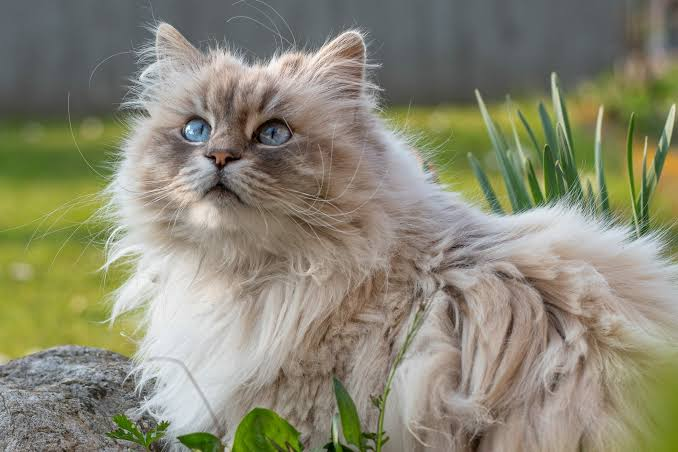

In [89]:
import base64, time

def analyze_image(path, model):
    with open(path, "rb") as f:
        b64 = base64.b64encode(f.read()).decode()
    prompt = """Analyze this image.

Identify:
1. Main objects
2. Environment
3. Text visible in the image
4. Possible interpretation"""
    payload = {
        "model": model,
        "messages": [{"role": "user", "content": prompt, "images": [b64]}],
        "stream": False,
        "think": False,
    }
    t0 = time.perf_counter()
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    if not r.ok:
        raise SystemExit(f"{r.status_code}: {r.text}")
    data = r.json()
    return {
        "response": data["message"]["content"],
        "wall_s": time.perf_counter() - t0,
    }

if os.path.exists(IMAGE_PATH):
    out = analyze_image(IMAGE_PATH, VISION_MODEL)
    print(out["response"], f"\n⏱ {out['wall_s']:.1f}s")
    from IPython.display import Image, display
    display(Image(IMAGE_PATH, width=400))
else:
    print(f"⚠️ Put an image named '{IMAGE_PATH}' next to this notebook, then re-run.")

### Questions
- Difference between an LLM and a multimodal model?
- What additional information does the vision model receive?
- Which applications could use local vision AI? *(document analysis, OCR, industrial inspection, education, medical-image preprocessing, surveillance analysis…)*

**✍️ Your answer:**

Difference between an LLM and a multimodal model?

An LLM only reads and writes text. A multimodal model accepts more than one kind of input. Here it received the written prompt and the pixels of image.jpg, then answered in text (76.3 s).

What additional information does the vision model receive?

The image itself, sent as a base64 string in the images field. A text-only model would only have seen “Analyze this image” and could not have described the Persian cat, the garden, or the fact that no writing is visible.

Which applications could use local vision AI?

The same local call can summarize a scanned document, read text in a photo (OCR; this picture had none), flag a visible defect on a part, explain a figure in class, give a first look at a medical image before a specialist reviews it, or describe a camera frame without uploading it.

## Part 15 — Build a Local AI Web Application
Structure:
```
local-ai-web/
├── app.py
├── templates/index.html
└── static/
```

In [67]:
!pip install -q flask requests
os.makedirs("local-ai-web/templates", exist_ok=True)
os.makedirs("local-ai-web/static", exist_ok=True)


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [92]:
%%writefile local-ai-web/app.py
from flask import Flask, render_template, request
import requests

app = Flask(__name__)

OLLAMA_URL = "http://localhost:11434/api/generate"
MODEL = "qwen3.5:0.8b"


@app.route("/", methods=["GET", "POST"])
def index():
    answer = ""

    if request.method == "POST":
        question = request.form["question"]
        data = {
            "model": MODEL,
            "prompt": question,
            "stream": False,
            "think": False,
        }
        response = requests.post(OLLAMA_URL, json=data, timeout=600)
        payload = response.json()
        answer = payload.get("response") or payload.get("error") or str(payload)

    return render_template("index.html", answer=answer)


if __name__ == "__main__":
    app.run(debug=True)

Overwriting local-ai-web/app.py


In [93]:
%%writefile local-ai-web/templates/index.html
<!DOCTYPE html>
<html>
<head>
    <title>Local AI Assistant</title>
</head>
<body>

<h1>Local AI Assistant</h1>

<form method="POST">
    <textarea name="question" rows="8" cols="70" placeholder="Ask your local AI..."></textarea>
    <br><br>
    <button type="submit">Ask</button>
</form>

{% if answer %}
<h2>Response</h2>
<pre>{{ answer }}</pre>
{% endif %}

</body>
</html>

Overwriting local-ai-web/templates/index.html


Run it **from a terminal** (not inside the notebook):
```bash
cd local-ai-web
python app.py
```
then open <http://127.0.0.1:5000>. 🎉 You now have a complete local AI web application.

*(📸 Take a screenshot for your report: `screenshots/06_webapp.png`.)*

## Part 16 — Performance Benchmark
We measure: response time, model size, tokens generated, tokens/second, RAM and GPU consumption.

Ollama returns precise counters: `eval_count` (generated tokens), `eval_duration` (ns), `prompt_eval_count`, `load_duration`.

In [71]:
!pip install -q psutil


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [72]:
%%writefile benchmark.py
"""Benchmark local Ollama models on the same prompt."""
import time, requests, psutil, pandas as pd

OLLAMA = "http://localhost:11434"
PROMPT = "Write a 500-word explanation of reinforcement learning."


def unload(model):
    requests.post(f"{OLLAMA}/api/generate", json={"model": model, "keep_alive": 0})
    time.sleep(2)


def loaded_info(model):
    for m in requests.get(f"{OLLAMA}/api/ps").json()["models"]:
        if m["name"].startswith(model.split(":")[0]):
            return m["size"] / 1e9, m.get("size_vram", 0) / 1e9
    return float("nan"), float("nan")


def bench(model, prompt=PROMPT, runs=1):
    rows = []
    for _ in range(runs):
        unload(model)                       # cold start, so the load time is visible
        t0 = time.perf_counter()
        r = requests.post(f"{OLLAMA}/api/generate",
                          json={"model": model, "prompt": prompt, "stream": False,
                                "think": False}, timeout=900).json()
        wall = time.perf_counter() - t0
        total_gb, vram_gb = loaded_info(model)
        rows.append({
            "Model": model,
            "Disk size (GB)": next((m["size"] / 1e9 for m in requests.get(f"{OLLAMA}/api/tags").json()["models"]
                                    if m["name"].startswith(model.split(":")[0])), float("nan")),
            "Loaded size (GB)": total_gb,
            "VRAM (GB)": vram_gb,
            "Load time (s)": r.get("load_duration", 0) / 1e9,
            "Response time (s)": wall,
            "Tokens": r.get("eval_count"),
            "Tokens/s": r["eval_count"] / (r["eval_duration"] / 1e9),
            "System RAM used (%)": psutil.virtual_memory().percent,
        })
    return pd.DataFrame(rows)


if __name__ == "__main__":
    import sys
    print(pd.concat([bench(m) for m in sys.argv[1:]]).round(2).to_string(index=False))

Writing benchmark.py


In [73]:
import benchmark; importlib.reload(benchmark)

bench_df = pd.concat([benchmark.bench(m) for m in (MODEL, MODEL2)], ignore_index=True)
bench_df["Quality /5"] = None   # <- fill in after reading both answers
bench_df.round(2)

,Model,Disk size (GB),Loaded size (GB),VRAM (GB),Load time (s),Response time (s),Tokens,Tokens/s,System RAM used (%),Quality /5
0,qwen3.5:0.8b,1.32,0.57,0.0,14.48,124.45,636,6.15,96.9,None
1,gemma3:1b,0.81,0.88,0.0,4.85,109.31,863,8.63,96.4,None


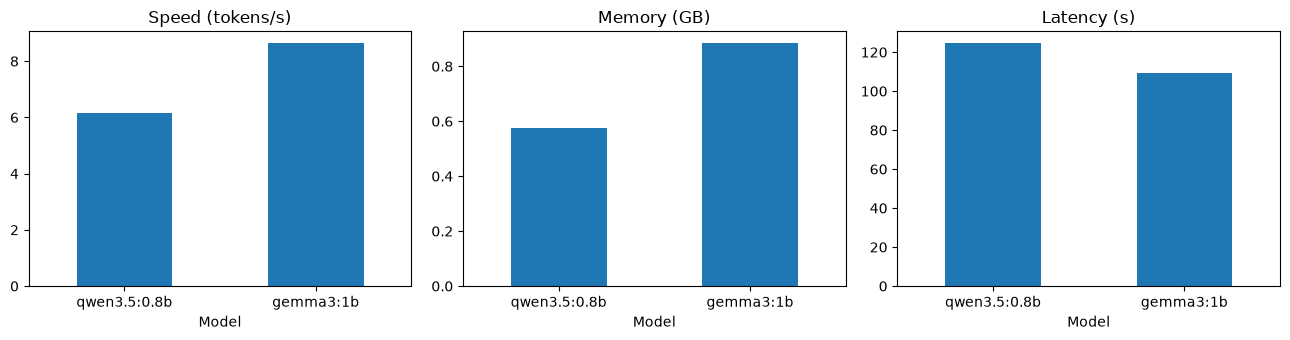

In [74]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
bench_df.plot.bar(x="Model", y="Tokens/s", ax=ax[0], legend=False, title="Speed (tokens/s)", rot=0)
bench_df.plot.bar(x="Model", y="Loaded size (GB)", ax=ax[1], legend=False, title="Memory (GB)", rot=0)
bench_df.plot.bar(x="Model", y="Response time (s)", ax=ax[2], legend=False, title="Latency (s)", rot=0)
plt.tight_layout(); plt.show()

### Discussion — the model-size trade-off
```
Model size ──► Quality
           ──► Memory
           ──► Latency
           ──► Hardware requirements
```
Local model selection should be based on **actual measurements on the target machine**, not just public benchmark rankings.

**✍️ Your discussion:**

On this machine both models ran on CPU and pushed system RAM to about 96%. The same prompt (“Write a 500-word explanation of reinforcement learning”) gave:

Model	Disk	Loaded	Load	Response	Tokens	Tokens/s	RAM
qwen3.5:0.8b
1.32 GB
0.57 GB
14.48 s
124.45 s
636
6.15
96.9%
gemma3:1b
0.81 GB
0.88 GB
4.85 s
109.31 s
863
8.63
96.4%
Gemma is smaller on disk and faster here: it loads in 4.85 s instead of 14.48 s, answers in 109 s instead of 124 s, and produces 8.63 tokens/s instead of 6.15. It also writes more tokens (863 vs 636). Quality was left empty in the table, so this comparison is about speed and memory.

Disk size is not the whole story. Gemma uses more RAM once loaded (0.88 GB vs 0.57 GB) even though its file is smaller. A larger model is not only slower on this PC: qwen3.5:latest (about 6.6 GB) failed to start because Ollama could not allocate a 3.2 GB CPU buffer. With RAM already near 97% for the small models, that tag cannot run.

The practical choice is the model that fits. Gemma3:1b is the faster of the two that load. Qwen3.5:0.8b uses less memory once loaded. A public ranking would not have shown that the 6.6 GB model does not start on this machine.

## Part 17 — Final Mini Project: **FSTT Local AI Assistant**

**Functional requirements:** runs entirely locally · uses Ollama + a local LLM · web interface · answers questions about a supplied course · uses local documents as knowledge · maintains conversation history · structured responses for selected questions · displays the answer · records response time.

```
Browser → Flask/Python ─┬─ Conversation history ─┐
                        └─ Documents → Retriever ┴─► Ollama → Local LLM
```

We reuse `rag.py` and create the final deliverable layout:
```
LocalAI_Lab/
├── source/ (app.py, chatbot.py, rag.py, benchmark.py, templates/)
├── documents/
├── screenshots/
├── report.pdf
└── README.md
```

In [75]:
import shutil
base = "LocalAI_Lab"
for d in ("source/templates", "documents", "screenshots"):
    os.makedirs(f"{base}/{d}", exist_ok=True)

# copy shared modules and documents into the deliverable layout
shutil.copy("rag.py", f"{base}/source/rag.py")
shutil.copy("benchmark.py", f"{base}/source/benchmark.py")
for fn in os.listdir("documents"):
    shutil.copy(f"documents/{fn}", f"{base}/documents/{fn}")
print(sorted(os.listdir(base)))

['documents', 'screenshots', 'source']


In [94]:
%%writefile LocalAI_Lab/source/chatbot.py
"""Console chatbot with conversation memory (uses /api/chat)."""
import requests

OLLAMA = "http://localhost:11434"
MODEL = "qwen3.5"


def main():
    messages = [{"role": "system", "content": "You are a helpful, concise assistant."}]
    print("Local AI Assistant — type 'exit' to stop.")
    while True:
        q = input("\nYou: ")
        if q.lower() == "exit":
            break
        messages.append({"role": "user", "content": q})
        r = requests.post(f"{OLLAMA}/api/chat",
                          json={"model": MODEL, "messages": messages, "stream": False})
        r.raise_for_status()
        reply = r.json()["message"]
        messages.append({"role": "assistant", "content": reply["content"]})
        print("\nAI:", reply["content"])


if __name__ == "__main__":
    main()

Writing LocalAI_Lab/source/chatbot.py


In [95]:
%%writefile LocalAI_Lab/source/app.py
"""FSTT Local AI Assistant — Flask + Ollama + local RAG + conversation history."""
import json, os, time
import requests
from flask import Flask, jsonify, render_template, request

import rag

OLLAMA = os.environ.get("OLLAMA_URL", "http://localhost:11434")
MODEL = os.environ.get("MODEL", "qwen3.5")
DOC_DIR = os.path.join(os.path.dirname(__file__), "..", "documents")
MAX_TURNS = 6                      # remembered user/assistant pairs

app = Flask(__name__)
retriever = rag.Retriever(rag.load_documents(DOC_DIR))
history = []                       # [{"role": ..., "content": ...}]  (single-user demo)

SYSTEM = ("You are the FSTT Local AI Assistant. Answer questions about the course using only the "
          "provided CONTEXT. If the answer is not in the context, say: \"Information not available.\" "
          "Be concise.")

# Structured response schema used for "Analyze ..." / "Quiz ..." style questions
STRUCT_SCHEMA = {
    "type": "object",
    "properties": {
        "topic": {"type": "string"},
        "summary": {"type": "string"},
        "key_points": {"type": "array", "items": {"type": "string"}},
        "difficulty": {"type": "string", "enum": ["easy", "medium", "hard"]},
    },
    "required": ["topic", "summary", "key_points", "difficulty"],
}


def call_ollama(messages, structured=False):
    payload = {"model": MODEL, "messages": messages, "stream": False, "think": False}
    if structured:
        payload["format"] = STRUCT_SCHEMA
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()


@app.route("/")
def index():
    return render_template("index.html", model=MODEL, docs=list(retriever.docs))


@app.route("/ask", methods=["POST"])
def ask():
    body = request.get_json(force=True)
    question = (body.get("question") or "").strip()
    structured = bool(body.get("structured"))
    if not question:
        return jsonify(error="Empty question"), 400

    hits, context = retriever.context(question, k=2)
    user_msg = f"CONTEXT:\n{context or '(none)'}\n\nQUESTION: {question}"
    messages = [{"role": "system", "content": SYSTEM}] + history[-2 * MAX_TURNS:] \
               + [{"role": "user", "content": user_msg}]

    t0 = time.perf_counter()
    try:
        out = call_ollama(messages, structured)
    except requests.RequestException as e:
        return jsonify(error=f"Ollama error: {e}"), 502
    elapsed = time.perf_counter() - t0

    answer = out["message"]["content"]
    # store the plain question (not the long context) to keep history small
    history.append({"role": "user", "content": question})
    history.append({"role": "assistant", "content": answer})

    parsed = None
    if structured:
        try:
            parsed = json.loads(answer)
        except json.JSONDecodeError:
            pass

    tokens = out.get("eval_count")
    tps = tokens / (out["eval_duration"] / 1e9) if tokens and out.get("eval_duration") else None
    return jsonify(answer=answer, structured=parsed,
                   sources=[{"doc": n, "score": round(s, 2)} for n, s in hits],
                   seconds=round(elapsed, 2), tokens=tokens,
                   tokens_per_s=round(tps, 1) if tps else None)


@app.route("/reset", methods=["POST"])
def reset():
    history.clear()
    return jsonify(ok=True)


if __name__ == "__main__":
    # Bind to localhost ONLY (see report question Q15 on security)
    app.run(host="127.0.0.1", port=int(os.environ.get("PORT", 5001)), debug=False)

Writing LocalAI_Lab/source/app.py


In [96]:
%%writefile LocalAI_Lab/source/templates/index.html
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<title>FSTT Local AI Assistant</title>
<style>
  body { font-family: system-ui, sans-serif; max-width: 820px; margin: 2rem auto; padding: 0 1rem; color:#222; }
  h1 { margin-bottom: .2rem; } .sub { color:#666; font-size:.9rem; margin-bottom:1rem; }
  #chat { border:1px solid #ddd; border-radius:8px; padding:1rem; height:420px; overflow-y:auto; background:#fafafa; }
  .msg { margin:.6rem 0; padding:.6rem .8rem; border-radius:8px; white-space:pre-wrap; }
  .user { background:#e3f0ff; } .ai { background:#fff; border:1px solid #e5e5e5; }
  .meta { font-size:.75rem; color:#777; margin-top:.3rem; }
  form { display:flex; gap:.5rem; margin-top:1rem; } input[type=text] { flex:1; padding:.6rem; }
  button { padding:.6rem 1rem; cursor:pointer; } label { font-size:.85rem; }
</style>
</head>
<body>
<h1>🎓 FSTT Local AI Assistant</h1>
<div class="sub">Model: <b>{{ model }}</b> · Documents: {{ docs|join(", ") }} · Runs 100% locally</div>
<div id="chat"></div>
<form id="f">
  <input type="text" id="q" placeholder="Ask a question about the course..." autocomplete="off" autofocus>
  <button type="submit">Ask</button>
  <button type="button" id="reset">Reset</button>
</form>
<label><input type="checkbox" id="struct"> Structured response (JSON)</label>

<script>
const chat = document.getElementById("chat");
function add(cls, text, meta) {
  const d = document.createElement("div"); d.className = "msg " + cls; d.textContent = text;
  if (meta) { const m = document.createElement("div"); m.className = "meta"; m.textContent = meta; d.appendChild(m); }
  chat.appendChild(d); chat.scrollTop = chat.scrollHeight; return d;
}
document.getElementById("f").onsubmit = async (e) => {
  e.preventDefault();
  const q = document.getElementById("q"); const question = q.value.trim(); if (!question) return;
  q.value = ""; add("user", question);
  const wait = add("ai", "…thinking…");
  try {
    const r = await fetch("/ask", {method:"POST", headers:{"Content-Type":"application/json"},
      body: JSON.stringify({question, structured: document.getElementById("struct").checked})});
    const j = await r.json(); wait.remove();
    if (j.error) { add("ai", "⚠️ " + j.error); return; }
    const text = j.structured ? JSON.stringify(j.structured, null, 2) : j.answer;
    const src = j.sources.map(s => s.doc).join(", ") || "none";
    add("ai", text, `⏱ ${j.seconds}s · ${j.tokens ?? "?"} tokens · ${j.tokens_per_s ?? "?"} tok/s · sources: ${src}`);
  } catch (err) { wait.remove(); add("ai", "⚠️ " + err); }
};
document.getElementById("reset").onclick = async () => { await fetch("/reset", {method:"POST"}); chat.innerHTML = ""; };
</script>
</body>
</html>

Writing LocalAI_Lab/source/templates/index.html


In [97]:
%%writefile LocalAI_Lab/README.md
# FSTT Local AI Assistant

A fully local assistant: Flask web UI → Ollama → local LLM, with a keyword (TF-IDF) retriever over `documents/`,
conversation history, structured (JSON) answers and response-time display.

## Setup
```bash
ollama pull qwen3.5
pip install flask requests psutil pandas
```

## Run
```bash
cd source
python app.py            # http://127.0.0.1:5001
python chatbot.py        # console chatbot
python benchmark.py qwen3.5 gemma3
```
Environment variables: `MODEL`, `OLLAMA_URL`, `PORT`.

Writing LocalAI_Lab/README.md


**Test the final app from the notebook:** launch it as a background process, send a few questions, then stop it.

In [99]:
import subprocess, sys, time

env = {**os.environ, "MODEL": MODEL, "PORT": "5001"}
server = subprocess.Popen([sys.executable, "app.py"], cwd="LocalAI_Lab/source", env=env,
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
time.sleep(3)

def app_ask(q, structured=False):
    r = requests.post("http://127.0.0.1:5001/ask", json={"question": q, "structured": structured}, timeout=600)
    return r.json()

try:
    for q, s in [("What is reinforcement learning?", False),
                 ("And how is it different from supervised learning?", False),   # tests history
                 ("Summarize deep learning", True),                              # structured
                 ("What is quantum computing?", False)]:                         # not in the docs
        j = app_ask(q, s)
        print(f"Q: {q}\nA: {j.get('structured') or j.get('answer') or j}\n"
              f"   sources={j.get('sources')} · {j.get('seconds')}s · {j.get('tokens_per_s')} tok/s\n")
finally:
    pass  # keep running so you can open http://127.0.0.1:5001 — stop in the next cell

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [100]:
server.terminate(); server.wait(timeout=10)
print("Server stopped.")

Server stopped.


> 📸 Open <http://127.0.0.1:5001> in your browser while the server is running and take your screenshots: `01_installation.png`, `02_model.png`, `03_chatbot.png`, `04_python.png`, `05_rag.png`, `06_webapp.png`.

## Part 18 — Questions for the Report
Answer each question in your own words (use your measurements from Parts 6 and 16 for Q13–Q14).

**Q1.** What is Local AI?

*Local AI is artificial intelligence that runs directly on a local computer instead of relying entirely on a remote server or cloud service. It allows users to run AI models on their own hardware.*

**Q2.** Difference between a Cloud LLM and a Local LLM?

*A Cloud LLM runs on remote servers and is accessed through the internet or an API. A Local LLM runs on the user's computer. Cloud models may offer more computing power, while local models provide greater control over data and can work without an internet connection after installation.*

**Q3.** What role does Ollama play?

*Ollama is a tool that allows users to download, manage, and run large language models locally. It simplifies model installation and provides an API that applications can use to send prompts and receive generated responses.*

**Q4.** What is model quantization?

*Model quantization is a technique that reduces the precision used to represent a model's weights, for example, from 16-bit to 4-bit values. This reduces memory consumption and can improve inference speed, although it may slightly reduce the model's accuracy or response quality.*

**Q5.** Why does model size affect memory consumption?

*A model contains parameters called weights that must be loaded into memory during inference. Larger models have more parameters and therefore require more memory. Additional memory is also needed for the context, intermediate calculations, and generated tokens.*

**Q6.** Why can a smaller model sometimes be preferable?

*A smaller model requires less RAM, can generate responses faster, and can run on computers with limited hardware resources. For simple tasks, it may provide sufficient quality without the additional cost and memory requirements of a larger model.*

**Q7.** Advantages of local inference?

*The main advantages of local inference are:
- Privacy: Data can remain on the local computer.
- Offline access: The model can run without an internet connection once installed.
- Lower recurring costs: There may be no per-request cloud API fees.
- Control: Users can choose and configure their models.
- Reduced network dependency: Inference does not depend on the availability of an external AI service.*

**Q8.** Disadvantages of local inference?

*Local inference requires sufficient RAM, storage, and processing power. It may be slower than cloud inference on computers with limited hardware. Smaller local models can also produce less accurate responses than larger models, and users are responsible for installation, updates, maintenance, and security.*

**Q9.** Explain the architecture of your Python application.

*My Python application uses a modular architecture. The Python backend receives requests from the user interface, processes the input, communicates with the local LLM through Ollama, and returns the generated response.

The main components are:
1. User interface: Allows users to enter prompts and view responses.
2. Python backend: Handles application logic, validates requests, and coordinates the different components.
3. REST API: Provides communication between the interface and the backend.
4. Ollama: Loads and runs the selected local language model.
5. LLM: Generates responses based on the provided prompts and context.
6. Response handling: Returns the generated text to the user interface.
If RAG is enabled, the application can also retrieve relevant information from documents and provide it to the model as additional context.*

**Q10.** Explain the role of the REST API.

*A REST API allows different parts of an application to communicate through HTTP requests. In my application, it allows the user interface to send prompts to the Python backend and receive the generated responses.

It separates the frontend from the backend, making the application easier to maintain, test, and integrate with other services.*

**Q11.** What is RAG?

*RAG stands for Retrieval-Augmented Generation. It is a technique that combines information retrieval with text generation.

First, the application searches a knowledge base or a collection of documents for relevant information. Then, it provides the retrieved information to the LLM as context for generating an answer.

RAG can improve the relevance of responses and allow a model to answer questions about specific documents without retraining the model.*

**Q12.** Difference between an LLM and a multimodal LLM?

*A traditional LLM primarily processes and generates text. A multimodal LLM can work with multiple types of data, such as text and images, and some models also support audio or video.

For example, a text-only LLM can answer a written question, while a multimodal LLM may analyze an image and answer questions about its contents.*

**Q13.** Compare two local models experimentally.

*(answer + table from Part 16)*

**Q14.** Which model would you deploy on a computer with limited RAM? Explain.

*(answer)*

**Q15.** What security risks exist when exposing a local LLM server to a network?

*(Hint: Ollama has no authentication by default; think about `OLLAMA_HOST=0.0.0.0`, unauthorized use of your compute, model/data exposure, prompt injection through documents, and what a reverse proxy with auth/TLS or a firewall would change.)*

## Part 19 — Deliverables
Final check of the submission folder:
```
LocalAI_Lab/
├── report.pdf
├── source/        app.py · chatbot.py · rag.py · benchmark.py
├── documents/     ai.txt · ml.txt · rl.txt  (+ the other course files)
├── screenshots/   01_installation.png … 06_webapp.png
└── README.md
```

In [ ]:
required = [
    "LocalAI_Lab/report.pdf",
    "LocalAI_Lab/README.md",
    "LocalAI_Lab/source/app.py", "LocalAI_Lab/source/chatbot.py",
    "LocalAI_Lab/source/rag.py", "LocalAI_Lab/source/benchmark.py",
    "LocalAI_Lab/screenshots/01_installation.png", "LocalAI_Lab/screenshots/02_model.png",
    "LocalAI_Lab/screenshots/03_chatbot.png", "LocalAI_Lab/screenshots/04_python.png",
    "LocalAI_Lab/screenshots/05_rag.png", "LocalAI_Lab/screenshots/06_webapp.png",
]
for p in required:
    print("✅" if os.path.exists(p) else "⬜ missing", p)
print("\nDocuments:", sorted(os.listdir("LocalAI_Lab/documents")))